# Regressão com Spark ML: estimativa de PM2.5 em Pequim
**Disciplina:** Processamento de Dados Massivos · **Professor:** Alexandre Roriz  
**Aluno:** Asafe Ferreira Gomes

**Tema:** Regressão · **Base:** Beijing Multi-Site Air Quality (UCI)

## Objetivo e pergunta de negócio
É possível estimar a concentração horária de PM2.5 (µg/m³) com meteorologia, calendário e identificação da estação, superando uma previsão constante pela média histórica?

O caso de uso é apoiar a identificação de leituras incomuns e a estimativa auxiliar quando um sensor de PM2.5 está indisponível. É uma **estimativa contemporânea**, pois utiliza meteorologia da mesma hora; não é uma previsão antecipada nem substitui equipamentos de monitoramento. Outros poluentes são excluídos para evitar depender de sensores adicionais que também poderiam estar indisponíveis.

### Base e contexto de dados massivos
A [base original da UCI](https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality+data), DOI [10.24432/C5RK5G](https://doi.org/10.24432/C5RK5G), contém **420.768 linhas**, **18 colunas** e **12 estações**, de **01/03/2013 a 28/02/2017**. A licença é CC BY 4.0. Cada linha representa uma estação em uma hora. Usamos todos os 12 arquivos, sem amostragem para treinamento. As exclusões de qualidade são contabilizadas abaixo.

Esta base histórica cabe em uma máquina e, isoladamente, não exige um cluster. Ela representa um recorte de um cenário de monitoramento contínuo: 10.000 sensores a cada minuto gerariam 5,256 bilhões de registros por ano (10.000 × 60 × 24 × 365). Nesse cenário, volume acumulado, velocidade de chegada e variedade de sensores justificam armazenamento particionado e processamento distribuído. Spark permite distribuir agregações, junções e treinamento; neste experimento usamos execução local, sem alegar ganho de desempenho de cluster. A medição de escalabilidade exigiria comparar tempos, custos e diferentes números de executores.

### Como reproduzir
Execute todas as células, na ordem, em Jupyter ou Google Colab. Recomenda-se Python 3.10–3.12, Java 11/17 e pelo menos 4 GB de RAM disponíveis. A instalação e o download precisam de internet. No Windows, a persistência do Spark também requer os componentes Hadoop nativos compatíveis (`winutils.exe` e `hadoop.dll`); Colab/Linux evita essa configuração. Os dados e modelos ficam em subpastas locais e **não devem ser enviados ao GitHub**.

In [1]:
import sys, subprocess, importlib.util
pacotes = {"setuptools": "setuptools==80.9.0", "pyspark": "pyspark==3.5.3", "matplotlib": "matplotlib"}
faltantes = [pacote for modulo, pacote in pacotes.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *faltantes])
import setuptools  # ativa a compatibilidade distutils no Python 3.12

In [2]:
import os, shutil
from pathlib import Path
if not os.environ.get("JAVA_HOME") and not shutil.which("java"):
    if importlib.util.find_spec("jdk4py") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "jdk4py==17.0.9.2"])
    from jdk4py import JAVA_HOME
    os.environ["JAVA_HOME"] = str(JAVA_HOME)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")
from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
def tabela(registros):
    colunas = list(registros[0])
    texto = " | ".join(colunas) + "\n" + " | ".join(["---"] * len(colunas)) + "\n"
    texto += "\n".join(" | ".join(f"{r[c]:.4f}" if isinstance(r[c], float) else str(r[c]) for c in colunas) for r in registros)
    display(Markdown(texto))
def coluna(registros, nome):
    return [r[nome] for r in registros]
spark = (SparkSession.builder.master("local[2]").appName("Trabalho-SparkML-Regressao")
         .config("spark.driver.memory", "3g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.session.timeZone", "UTC").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Python:", sys.version.split()[0], "| Spark:", spark.version)

Python: 3.13.18 | Spark: 4.0.5


## 1. Ingestão reproduzível e esquema explícito
Os CSVs são baixados da fonte original. O ZIP pode conter outro ZIP; o código lê ambos sem depender de uma pasta pré-existente. O esquema é definido manualmente, evitando inferência e leituras extras. `NA` representa ausência. A coluna `PM2.5` é renomeada para `label` para evitar a interpretação do ponto como acesso a campo aninhado.

In [3]:
import urllib.request, zipfile, io, hashlib
PASTA = Path.cwd() / "dados_beijing"
PASTA.mkdir(exist_ok=True)
URL = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"
arquivo_zip = PASTA / "original.zip"
if not arquivo_zip.exists():
    urllib.request.urlretrieve(URL, arquivo_zip)
def extrair_csv(conteudo):
    with zipfile.ZipFile(io.BytesIO(conteudo)) as z:
        for nome in z.namelist():
            if nome.lower().endswith(".zip"):
                extrair_csv(z.read(nome))
            elif nome.lower().endswith(".csv"):
                (PASTA / Path(nome).name).write_bytes(z.read(nome))
extrair_csv(arquivo_zip.read_bytes())
arquivos = sorted(PASTA.glob("PRSA_Data_*.csv"))
assert len(arquivos) == 12, f"Esperados 12 CSVs; encontrados {len(arquivos)}"
print("Fonte:", URL)
print("SHA-256 do download:", hashlib.sha256(arquivo_zip.read_bytes()).hexdigest())
print("Arquivos:", len(arquivos))
schema = T.StructType([
    *[T.StructField(c, T.IntegerType(), True) for c in ["No", "year", "month", "day", "hour"]],
    *[T.StructField(c, T.DoubleType(), True) for c in
      ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN"]],
    T.StructField("wd", T.StringType(), True),
    T.StructField("WSPM", T.DoubleType(), True),
    T.StructField("station", T.StringType(), True)])
raw = (spark.read.option("header", True).option("nullValue", "NA")
       .option("mode", "FAILFAST").schema(schema)
       .csv([p.as_posix() for p in arquivos]).withColumnRenamed("PM2.5", "label").cache())
n_original = raw.count()
assert n_original == 420768
print("Linhas:", n_original, "| Colunas:", len(raw.columns))
raw.printSchema()
raw.show(5, truncate=False)

Fonte: https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip
SHA-256 do download: b04da438b2f331ac0ffd45aebdfec0d20d2367feb5f6948c4b1f7ce1191e33c4
Arquivos: 12
Linhas: 420768 | Colunas: 18
root
 |-- No: integer (nullable = true)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- day: integer (nullable = true)
 |-- hour: integer (nullable = true)
 |-- label: double (nullable = true)
 |-- PM10: double (nullable = true)
 |-- SO2: double (nullable = true)
 |-- NO2: double (nullable = true)
 |-- CO: double (nullable = true)
 |-- O3: double (nullable = true)
 |-- TEMP: double (nullable = true)
 |-- PRES: double (nullable = true)
 |-- DEWP: double (nullable = true)
 |-- RAIN: double (nullable = true)
 |-- wd: string (nullable = true)
 |-- WSPM: double (nullable = true)
 |-- station: string (nullable = true)

+---+----+-----+---+----+-----+----+----+----+-----+----+----+------+-----+----+---+----+-------------+
|No |year|month|day|ho

## 2. Exploração e limpeza com Spark
Calculamos estatísticas e ausências de todas as colunas. Removemos duplicatas exatas. Para chaves estação/hora conflitantes, excluímos todas as linhas daquela chave, evitando escolher arbitrariamente uma medição. Alvos ausentes, não finitos ou negativos são excluídos: imputar o alvo criaria rótulos artificiais.

Temperatura e ponto de orvalho negativos são possíveis. Pressão não positiva, chuva ou vento negativos são inválidos e viram nulos; variáveis numéricas não finitas também viram nulos. Meteorologia ausente será imputada pela mediana **aprendida no treino**, dentro do Pipeline. Valores extremos válidos de poluição são preservados, pois episódios de pico são relevantes. Direções do vento desconhecidas viram uma categoria explícita.

In [4]:
raw.select([F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c)
            for c in raw.columns]).show(truncate=False)
raw.select("label", "TEMP", "PRES", "DEWP", "RAIN", "WSPM").summary().show()
raw.groupBy("station").count().orderBy("station").show(20, truncate=False)

+---+----+-----+---+----+-----+----+----+-----+-----+-----+----+----+----+----+----+----+-------+
|No |year|month|day|hour|label|PM10|SO2 |NO2  |CO   |O3   |TEMP|PRES|DEWP|RAIN|wd  |WSPM|station|
+---+----+-----+---+----+-----+----+----+-----+-----+-----+----+----+----+----+----+----+-------+
|0  |0   |0    |0  |0   |8739 |6449|9021|12116|20701|13277|398 |393 |403 |390 |1822|318 |0      |
+---+----+-----+---+----+-----+----+----+-----+-----+-----+----+----+----+----+----+----+-------+

+-------+-----------------+------------------+------------------+------------------+-------------------+------------------+
|summary|            label|              TEMP|              PRES|              DEWP|               RAIN|              WSPM|
+-------+-----------------+------------------+------------------+------------------+-------------------+------------------+
|  count|           412029|            420370|            420375|            420365|             420378|            420450|
|   mean| 79.

In [5]:
meteo = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
df = raw.dropDuplicates().cache()
n_sem_dup = df.count()
df = df.withColumn("data", F.to_date(F.concat_ws("-", "year", "month", "day")))
valido = (F.col("station").isNotNull() & (F.length(F.trim("station")) > 0)
          & F.col("data").isNotNull() & F.col("hour").between(0, 23)
          & F.col("label").isNotNull() & ~F.isnan("label")
          & (F.col("label") >= 0) & (F.col("label") < float("inf")))
df = df.filter(valido)
n_validos = df.count()
chaves = ["station", "data", "hour"]
conflitos = df.groupBy(*chaves).count().filter(F.col("count") > 1).select(*chaves)
df = df.join(conflitos, chaves, "left_anti")
for c in meteo:
    invalido = F.isnan(c) | (F.abs(F.col(c)) == float("inf"))
    if c == "PRES": invalido = invalido | (F.col(c) <= 0)
    if c in ["RAIN", "WSPM"]: invalido = invalido | (F.col(c) < 0)
    df = df.withColumn(c, F.when(invalido, F.lit(None).cast("double")).otherwise(F.col(c)))
direcoes = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
df = df.withColumn("wd", F.when(F.col("wd").isin(direcoes), F.col("wd")).otherwise("DESCONHECIDO")).cache()
n_limpo = df.count()
assert n_limpo >= 200000
print({"original": n_original, "duplicatas_exatas_removidas": n_original-n_sem_dup,
       "alvo_ou_identificacao_invalidos": n_sem_dup-n_validos,
       "linhas_com_chave_conflitante": n_validos-n_limpo,
       "linhas_utilizadas": n_limpo})
df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in meteo]).show()
df.select(F.min("data").alias("inicio"), F.max("data").alias("fim")).show()

{'original': 420768, 'duplicatas_exatas_removidas': 0, 'alvo_ou_identificacao_invalidos': 8739, 'linhas_com_chave_conflitante': 0, 'linhas_utilizadas': 412029}
+----+----+----+----+----+
|TEMP|PRES|DEWP|RAIN|WSPM|
+----+----+----+----+----+
| 398| 393| 403| 390| 317|
+----+----+----+----+----+

+----------+----------+
|    inicio|       fim|
+----------+----------+
|2013-03-01|2017-02-28|
+----------+----------+



### Visualização agregada
As médias mensais e por estação são calculadas no Spark. Somente as pequenas tabelas agregadas são trazidas para o driver para desenhar os gráficos; não usamos pandas para limpar ou treinar a base.

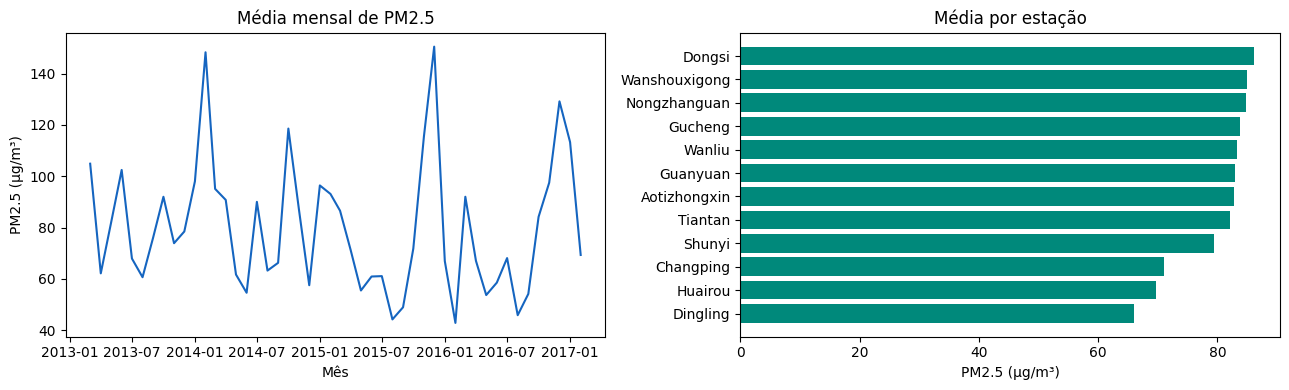

In [6]:
mensal = (df.groupBy(F.date_trunc("month", "data").alias("mes"))
          .agg(F.avg("label").alias("pm25"), F.count("*").alias("n"))
          .orderBy("mes").collect())
estacoes = df.groupBy("station").agg(F.avg("label").alias("pm25")).orderBy("pm25").collect()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(coluna(mensal, "mes"), coluna(mensal, "pm25"), color="#1565c0")
ax[0].set(title="Média mensal de PM2.5", ylabel="PM2.5 (µg/m³)", xlabel="Mês")
ax[1].barh(coluna(estacoes, "station"), coluna(estacoes, "pm25"), color="#00897b")
ax[1].set(title="Média por estação", xlabel="PM2.5 (µg/m³)")
plt.tight_layout(); plt.show()

## 3. Divisão temporal e atributos
Treino: março/2013–dezembro/2015; validação: janeiro–junho/2016; teste final: julho/2016–fevereiro/2017. Todas as estações de uma mesma hora ficam no mesmo conjunto. Isso evita o otimismo de uma divisão aleatória de observações temporalmente correlacionadas. O teste permanece reservado até a escolha da regularização.

Entradas: temperatura, pressão, ponto de orvalho, chuva, velocidade e direção do vento, estação, dia da semana e ciclos de hora e mês. Seno/cosseno preservam a proximidade entre 23h e 0h e entre dezembro e janeiro. `No`, ano absoluto e demais poluentes não entram. As transformações cíclicas são determinísticas; imputação, vocabulários categóricos e escala são ajustados exclusivamente pelo Pipeline no conjunto de treinamento correspondente.

In [7]:
import math
from pyspark.ml.feature import SQLTransformer
atributos_sql = SQLTransformer(statement="""
SELECT *,
 sin(2 * PI() * hour / 24) AS hora_sin,
 cos(2 * PI() * hour / 24) AS hora_cos,
 sin(2 * PI() * (month - 1) / 12) AS mes_sin,
 cos(2 * PI() * (month - 1) / 12) AS mes_cos,
 CAST(dayofweek(data) AS STRING) AS dia_semana
FROM __THIS__
""")
treino = df.filter(F.col("data") < "2016-01-01").cache()
validacao = df.filter((F.col("data") >= "2016-01-01") & (F.col("data") < "2016-07-01")).cache()
teste = df.filter(F.col("data") >= "2016-07-01").cache()
contagens = {nome: base.count() for nome, base in [("treino", treino), ("validacao", validacao), ("teste", teste)]}
assert sum(contagens.values()) == n_limpo and min(contagens.values()) > 0
print(contagens)

{'treino': 292150, 'validacao': 51343, 'teste': 68536}


## 4. Pipeline e ajuste de hiperparâmetros
A regressão linear regularizada (Ridge) é uma primeira abordagem interpretável e de menor custo computacional. Testamos `regParam` em **0, 0,1 e 10**, mantendo `elasticNetParam=0` (penalização L2). O primeiro valor é a regressão sem penalização; os demais testam regularização fraca e mais forte. A escolha usa apenas o menor RMSE na validação temporal, uma alternativa de menor custo à validação cruzada e coerente com a ordem temporal.

O Pipeline inclui transformação cíclica, imputação mediana, StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler e LinearRegression. A escala não centraliza os vetores para preservar sua esparsidade. A padronização interna do regressor é desabilitada porque já está explícita no Pipeline. Categorias inéditas são tratadas sem falhar. A mediana é aproximada (`relativeError=0.001`), apropriada a processamento em escala.

In [8]:
categoricas = ["station", "wd", "dia_semana"]
def criar_pipeline(reg):
    imputer = Imputer(inputCols=meteo, outputCols=[c+"_imp" for c in meteo],
                      strategy="median", relativeError=0.001)
    indices = [StringIndexer(inputCol=c, outputCol=c+"_idx", handleInvalid="keep") for c in categoricas]
    encoder = OneHotEncoder(inputCols=[c+"_idx" for c in categoricas],
                            outputCols=[c+"_ohe" for c in categoricas], handleInvalid="keep")
    assembler = VectorAssembler(inputCols=[c+"_imp" for c in meteo]
        + ["hora_sin", "hora_cos", "mes_sin", "mes_cos"]
        + [c+"_ohe" for c in categoricas], outputCol="features_raw")
    scaler = StandardScaler(inputCol="features_raw", outputCol="features", withStd=True, withMean=False)
    lr = LinearRegression(featuresCol="features", labelCol="label", regParam=reg,
                          elasticNetParam=0.0, standardization=False, maxIter=100, tol=1e-6)
    return Pipeline(stages=[atributos_sql, imputer, *indices, encoder, assembler, scaler, lr])
avaliador = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
busca = []
for reg in [0.0, 0.1, 10.0]:
    candidato = criar_pipeline(reg).fit(treino)
    rmse = avaliador.evaluate(candidato.transform(validacao))
    busca.append({"regParam": reg, "RMSE_validacao": rmse})
    print(f"regParam={reg:g} | RMSE validação={rmse:.4f}")
melhor = min(busca, key=lambda x: x["RMSE_validacao"])
tabela(sorted(busca, key=lambda x: x["RMSE_validacao"]))
print("Hiperparâmetro escolhido:", melhor["regParam"])

regParam=0 | RMSE validação=56.6132
regParam=0.1 | RMSE validação=56.5580
regParam=10 | RMSE validação=58.8065


regParam | RMSE_validacao
--- | ---
0.1000 | 56.5580
0.0000 | 56.6132
10.0000 | 58.8065

Hiperparâmetro escolhido: 0.1


## 5. Treinamento final e avaliação no teste
Depois da seleção, reajustamos todo o Pipeline em treino + validação, sem incluir o teste. A referência prevê a média do alvo nesse mesmo conjunto de desenvolvimento. RMSE penaliza erros grandes; MAE informa o erro absoluto médio em µg/m³; R² mede a proporção de variabilidade explicada em relação à média do próprio teste e pode ser negativo. A referência treinada no passado não precisa ter R² exatamente zero.

In [9]:
desenvolvimento = treino.unionByName(validacao).cache()
modelo = criar_pipeline(melhor["regParam"]).fit(desenvolvimento)
media_treino = desenvolvimento.agg(F.avg("label")).first()[0]
previsoes = modelo.transform(teste).cache()
referencia = teste.withColumn("prediction", F.lit(media_treino))
def metricas(pred):
    return {m.upper() if m != "r2" else "R²": RegressionEvaluator(
        labelCol="label", predictionCol="prediction", metricName=m).evaluate(pred)
        for m in ["rmse", "mae", "r2"]}
resultados = {"Média histórica": metricas(referencia), "Regressão Ridge": metricas(previsoes)}
tabela([{"Modelo": nome, **valores} for nome, valores in resultados.items()])
ganho = 100 * (1 - resultados["Regressão Ridge"]["RMSE"] / resultados["Média histórica"]["RMSE"])
print(f"Redução de RMSE frente à referência: {ganho:.2f}%")

Modelo | RMSE | MAE | R²
--- | --- | --- | ---
Média histórica | 89.2907 | 64.0369 | -0.0020
Regressão Ridge | 70.3193 | 50.1784 | 0.3785

Redução de RMSE frente à referência: 21.25%


### Diagnóstico dos erros e interpretação
A avaliação por estação identifica desigualdades que a média geral esconde. Resíduo é observado menos previsto: valor positivo significa subestimação. No gráfico por faixa, usamos médias de observado e previsto e contagens, todas calculadas em Spark; o gráfico mostra calibração agregada, não dispersão individual. Nenhuma decisão de ajuste é tomada com esses resultados do teste.

+-------------+----+------------------+-----------------+-------------------+
|station      |n   |MAE               |RMSE             |vies               |
+-------------+----+------------------+-----------------+-------------------+
|Wanshouxigong|5748|53.67020017021799 |78.52408038282854|0.7859681510668157 |
|Gucheng      |5730|52.42168133134387 |77.90628206300416|1.7609257578845765 |
|Dongsi       |5589|54.76601407284658 |77.37242176795935|-1.8899053858735737|
|Nongzhanguan |5740|53.26496728139479 |73.80467768204039|-5.192491841841377 |
|Shunyi       |5659|50.29648995627253 |70.8850645846027 |-6.548306790336554 |
|Guanyuan     |5680|49.895336144381965|70.76331853543154|2.3628770735075415 |
|Tiantan      |5757|50.80326855662453 |70.53655890111607|-5.578344568355786 |
|Wanliu       |5767|50.34957473033575 |69.8681337940378 |-4.745666038380809 |
|Aotizhongxin |5744|49.45593621708772 |69.31880549568747|-2.0136286148109783|
|Changping    |5766|46.47767683791008 |62.77633652972826|-12.459

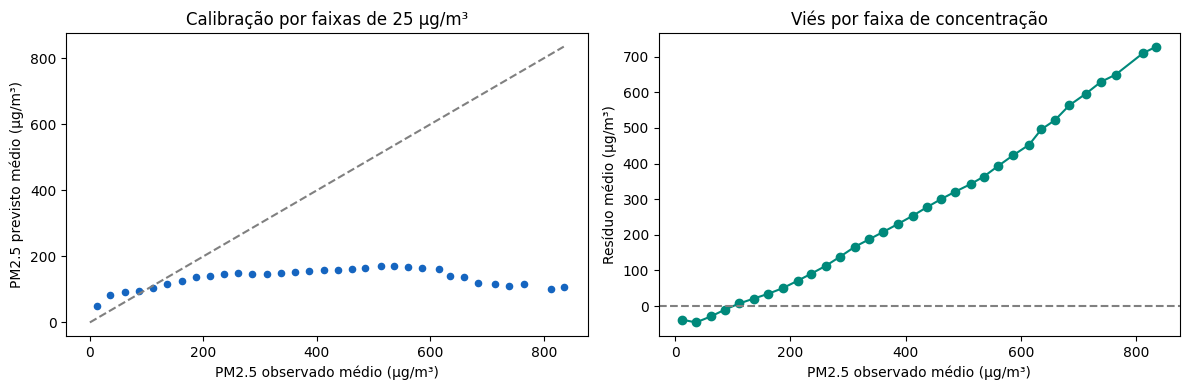

faixa | observado | previsto | residuo | n
--- | --- | --- | --- | ---
625 | 635.2941 | 139.6625 | 495.6316 | 17
650 | 658.8333 | 137.4318 | 521.4015 | 12
675 | 683.8571 | 120.7680 | 563.0891 | 7
700 | 713.0000 | 116.8152 | 596.1848 | 1
725 | 739.0000 | 109.7879 | 629.2121 | 4
750 | 764.5000 | 115.1147 | 649.3853 | 2
800 | 811.6667 | 102.3636 | 709.3031 | 3
825 | 835.0000 | 107.0669 | 727.9331 | 1

In [10]:
erros = previsoes.withColumn("residuo", F.col("label")-F.col("prediction"))
por_estacao = (erros.groupBy("station").agg(F.count("*").alias("n"),
    F.avg(F.abs("residuo")).alias("MAE"),
    F.sqrt(F.avg(F.pow("residuo", 2))).alias("RMSE"),
    F.avg("residuo").alias("vies")).orderBy(F.desc("RMSE")))
por_estacao.show(20, truncate=False)
negativas = previsoes.filter(F.col("prediction") < 0).count()
print(f"Previsões negativas: {negativas} de {contagens['teste']} ({100*negativas/contagens['teste']:.2f}%)")
calibracao = (erros.withColumn("faixa", F.floor(F.col("label") / 25) * 25)
    .groupBy("faixa").agg(F.avg("label").alias("observado"),
        F.avg("prediction").alias("previsto"), F.avg("residuo").alias("residuo"), F.count("*").alias("n"))
    .orderBy("faixa").collect())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(coluna(calibracao, "observado"), coluna(calibracao, "previsto"), s=20, color="#1565c0")
lim = max(max(coluna(calibracao, "observado")), max(coluna(calibracao, "previsto")))
ax[0].plot([0, lim], [0, lim], "--", color="gray")
ax[0].set(xlabel="PM2.5 observado médio (µg/m³)", ylabel="PM2.5 previsto médio (µg/m³)", title="Calibração por faixas de 25 µg/m³")
ax[1].plot(coluna(calibracao, "observado"), coluna(calibracao, "residuo"), "o-", color="#00897b")
ax[1].axhline(0, color="gray", linestyle="--")
ax[1].set(xlabel="PM2.5 observado médio (µg/m³)", ylabel="Resíduo médio (µg/m³)", title="Viés por faixa de concentração")
plt.tight_layout(); plt.show()
tabela([r.asDict() for r in calibracao[-8:]])

In [11]:
# Coeficientes: interpretação associativa, sem atribuir causalidade.
meta = previsoes.schema["features_raw"].metadata["ml_attr"]["attrs"]
nomes = {a["idx"]: a["name"] for grupo in meta.values() for a in grupo}
coeficientes = [{"atributo": nomes.get(i, str(i)), "coeficiente_escalado": float(c)}
               for i, c in enumerate(modelo.stages[-1].coefficients)]
tabela(sorted(coeficientes, key=lambda x: abs(x["coeficiente_escalado"]), reverse=True)[:12])

atributo | coeficiente_escalado
--- | ---
DEWP_imp | 90.7328
mes_cos | 80.1605
TEMP_imp | -24.5318
PRES_imp | -12.7926
mes_sin | 10.2832
hora_sin | -6.9860
hora_cos | -4.6628
WSPM_imp | -4.2927
station_ohe_Huairou | -3.6675
station_ohe_Dongsi | 2.2771
station_ohe_Dingling | -2.2410
wd_ohe_ESE | 2.0153

Os coeficientes correspondem a entradas divididas por seu desvio padrão e não são efeitos causais. Para variáveis numéricas, representam uma mudança de um desvio padrão, mantendo as demais entradas constantes. Indicadoras categóricas também foram escaladas, portanto não se deve interpretar diretamente seu coeficiente como a diferença bruta entre duas categorias. Colinearidade, sazonalidade e regularização afetam os valores.

## 6. Persistência e teste de recarga
Salvamos **todo o PipelineModel**, incluindo pré-processamento e regressor, usando `save()` do Spark ML. A pasta recebe um identificador único para não sobrescrever execuções anteriores. Em seguida, carregamos o modelo e verificamos se produz as mesmas previsões em 100 registros fixos do teste.

In [12]:
from datetime import datetime
destino = Path.cwd() / "modelos" / ("ridge_pm25_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
modelo.save(destino.as_posix())
if os.name == "nt":
    # Todas as etapas são JavaML: leitura JVM evita o worker Python no Windows.
    from pyspark.ml.util import JavaMLReader
    recarregado = JavaMLReader(PipelineModel).load(destino.as_posix())
else:
    recarregado = PipelineModel.load(destino.as_posix())
checagem = teste.orderBy("data", "hour", "station").limit(100).cache()
a = modelo.transform(checagem).select(*chaves, F.col("prediction").alias("antes"))
b = recarregado.transform(checagem).select(*chaves, F.col("prediction").alias("depois"))
diferenca = a.join(b, chaves).agg(F.max(F.abs(F.col("antes")-F.col("depois")))).first()[0]
assert diferenca is not None and diferenca < 1e-9
print("Pipeline salvo em:", destino)
print("Máxima diferença após recarga:", diferenca)

Pipeline salvo em: /content/modelos/ridge_pm25_20261105_134500_077743
Máxima diferença após recarga: 0.0


## 7. Conclusão baseada nos resultados executados
A célula seguinte produz a síntese a partir das métricas reais, sem resultados escritos manualmente. Os dados de teste não são usados para escolher hiperparâmetros nem para reajustar o modelo.

In [13]:
r = resultados["Regressão Ridge"]
comparacao = "superou" if ganho > 0 else "não superou"
display(Markdown(f"""
Foram ingeridos **{n_original:,} registros** e utilizados **{n_limpo:,}** após a limpeza.
A regularização escolhida na validação foi **{melhor['regParam']:g}**.
No teste temporal com **{contagens['teste']:,} registros**, a regressão obteve
**RMSE = {r['RMSE']:.2f} µg/m³**, **MAE = {r['MAE']:.2f} µg/m³** e **R² = {r['R²']:.3f}**.
O modelo **{comparacao}** a referência, com redução de RMSE de **{ganho:.2f}%**.

O MAE significa que as estimativas se afastaram das medições em cerca de **{r['MAE']:.1f} µg/m³**, em média.
Esses números quantificam a utilidade da abordagem no período reservado; não asseguram precisão em cada hora,
em outra cidade ou em anos futuros. A decisão de uso operacional depende da tolerância a erro do sistema de monitoramento.
"""))


Foram ingeridos **420,768 registros** e utilizados **412,029** após a limpeza.
A regularização escolhida na validação foi **0.1**.
No teste temporal com **68,536 registros**, a regressão obteve
**RMSE = 70.32 µg/m³**, **MAE = 50.18 µg/m³** e **R² = 0.379**.
O modelo **superou** a referência, com redução de RMSE de **21.25%**.

O MAE significa que as estimativas se afastaram das medições em cerca de **50.2 µg/m³**, em média.
Esses números quantificam a utilidade da abordagem no período reservado; não asseguram precisão em cada hora,
em outra cidade ou em anos futuros. A decisão de uso operacional depende da tolerância a erro do sistema de monitoramento.


### Limitações e melhorias
- A regressão linear não representa todas as interações entre dispersão, meteorologia e emissões. Árvores de regressão, Random Forest e GBT são próximos candidatos, sempre escolhidos em validação temporal.
- A omissão de outras fontes de emissões limita a explicação do alvo. PM2.5 alto pode ser subestimado; RMSE e gráficos por faixa ajudam a detectar isso. Faixas raras têm maior incerteza.
- Previsões negativas são fisicamente impossíveis. Elas são contabilizadas, mas não truncadas após olhar o teste. Uma transformação logarítmica do alvo ou restrição de saída deve ser validada em um novo experimento.
- A exclusão de alvos ausentes pode introduzir viés se falhas de medição ocorrerem durante episódios extremos. A imputação mediana não reproduz toda a dinâmica meteorológica.
- O teste cobre apenas oito meses; mudança de estação do ano, políticas ambientais e mudanças de sensores podem alterar o desempenho. Validação por janelas temporais sucessivas e um ano completo de teste melhorariam a robustez.
- Não estimamos intervalos de confiança nem medimos generalização para estações inéditas. A separação por estação seria necessária para avaliar esse segundo cenário.
- Uma extensão distribuída deveria armazenar os dados em Parquet particionado por ano/mês, revisar partições e medir custo, shuffle e tempo em cluster. Aqui `local[2]` demonstra a API, não escalabilidade medida.

### Relação com os critérios do trabalho
| Requisito | Onde foi atendido |
|---|---|
| Fonte pública, ≥200 mil registros e contexto massivo | Introdução e contagens verificadas |
| Ingestão PySpark com schema | Seção 1 |
| Nulos, inválidos, duplicatas e estatísticas Spark | Seção 2 |
| Atributos, codificação e padronização em Pipeline | Seções 3–4 |
| Treino/teste sem vazamento e hiperparâmetros | Seções 3–5 |
| RMSE, MAE, R², referência e interpretação | Seções 5 e 7 |
| Modelo salvo com save() e recarregado | Seção 6 |

### Referências e entrega
1. Chen, S. (2017). *Beijing Multi-Site Air Quality*. UCI Machine Learning Repository. [DOI e dados](https://doi.org/10.24432/C5RK5G). Licença CC BY 4.0.
2. Apache Spark. [ML Pipelines](https://spark.apache.org/docs/3.5.6/ml-pipeline.html).
3. Apache Spark. [Classification and regression — Linear regression](https://spark.apache.org/docs/3.5.6/ml-classification-regression.html#linear-regression).
4. Apache Spark. [Feature transformers](https://spark.apache.org/docs/3.5.6/ml-features.html).

